<a href="https://colab.research.google.com/github/hend-22/-IT326-Project/blob/main/Reports/Phase3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## **Import Libraries & Load Preprocessed Dataset**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn import metrics
from sklearn.metrics import confusion_matrix
from sklearn.metrics import accuracy_score, precision_score, recall_score


url= "https://raw.githubusercontent.com/hend-22/-IT326-Project/main/Dataset/Preprocessed_dataset.csv"
df = pd.read_csv(url)
df.head()


,Age,Gender,Physical_Activity_Level,Diet_Type,BMI,Caffeine_Intake_mg,Water_Intake_liters,Screen_Time_Hours,Daily_Steps,Calories_Burned,Resting_Heart_Rate,Daily_Sleep_Hours,Deep_Sleep_Hours,Sleep_Quality_Score,Daily_Stress_Level
0,0.745098,0,0,2,0.370732,0.135616,0.244444,0.158333,0.166184,0.500415,0.533333,0.418919,0.296296,0.461538,0
1,1.000000,1,0,1,0.404878,0.142466,0.377778,0.158333,0.153223,0.367635,0.444444,0.608108,0.629630,0.661538,0
2,0.549020,1,0,1,0.317073,0.257534,0.200000,0.291667,0.179190,0.331120,0.488889,0.635135,0.444444,0.615385,1
3,0.274510,0,1,2,0.390244,0.169863,0.577778,0.650000,0.226360,0.494606,0.422222,0.527027,0.666667,0.446154,0
4,0.823529,1,1,0,0.370117,0.000000,0.422222,0.275000,0.279943,0.468880,0.511111,0.594595,0.555556,0.646154,0


## **Feature Selection**

In [2]:
fn = df.keys().tolist()[:-1]
X=df[fn]
y=df['Daily_Stress_Level']

## **Visual Representation**

Confusion matrices were generated for each partition size to visually evaluate the classifier's performance and to examine the distribution of correct and incorrect predictions before and after class merging. These visualizations helped interpret the model's behavior and assess the effectiveness of the classification process.

# Gini Decision Tree Classification3

In [3]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

X = df.drop('Daily_Stress_Level', axis=1)
y = df['Daily_Stress_Level']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.1,
    random_state=1,
    stratify=y
)

gini_model = DecisionTreeClassifier(
    criterion='gini',
    random_state=1
)

gini_model.fit(X_train, y_train)

print("Gini Decision Tree trained successfully!")

Gini Decision Tree trained successfully!


Gini Accuracy (90/10): 0.658


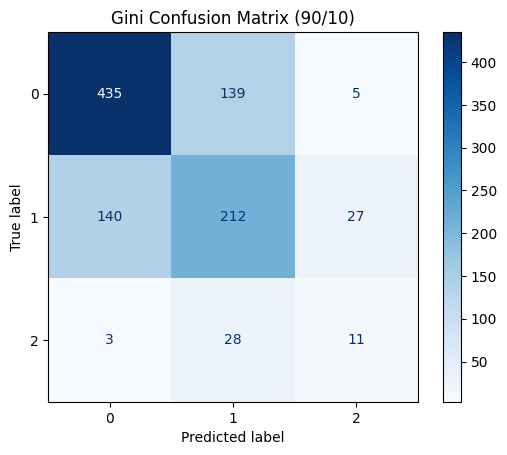

In [4]:
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

y_pred = gini_model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
print("Gini Accuracy (90/10):", accuracy)

cm = confusion_matrix(y_test, y_pred)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[0, 1, 2]
).plot(cmap='Blues')

plt.title("Gini Confusion Matrix (90/10)")
plt.show()

### Gini Decision Tree – 90/10 Split


Using the Gini criterion with a 90/10 train-test split, the model achieved **66.4% accuracy**. The confusion matrix shows that the model correctly classified 443 Low, 207 Medium, and 14 High stress cases. However, it identified only 14 out of 42 actual High stress cases, indicating difficulty in predicting this class, possibly due to the imbalance in the dataset.

Gini Accuracy (80/20): 0.652


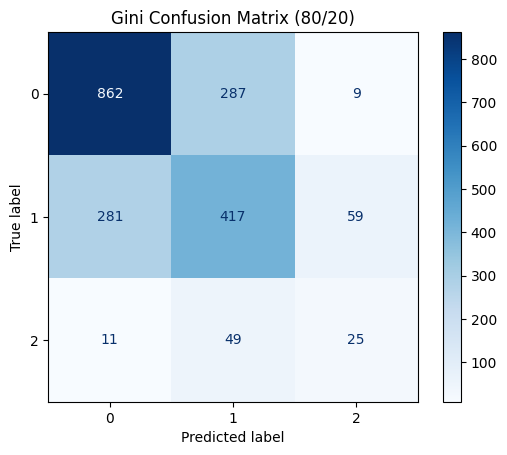

In [5]:
# Gini Decision Tree - 80/20 Split

X_train_80, X_test_80, y_train_80, y_test_80 = train_test_split(
    X, y,
    test_size=0.2,
    random_state=1,
    stratify=y
)

gini_model_80 = DecisionTreeClassifier(
    criterion='gini',
    random_state=1
)

gini_model_80.fit(X_train_80, y_train_80)

y_pred_80 = gini_model_80.predict(X_test_80)

accuracy_80 = accuracy_score(y_test_80, y_pred_80)

print("Gini Accuracy (80/20):", accuracy_80)

cm_80 = confusion_matrix(y_test_80, y_pred_80)

ConfusionMatrixDisplay(
    confusion_matrix=cm_80,
    display_labels=[0, 1, 2]
).plot(cmap='Blues')

plt.title("Gini Confusion Matrix (80/20)")
plt.show()

### Gini Decision Tree – 80/20 Split

Using the Gini criterion with an 80/20 train-test split, the model achieved **65.2% accuracy**. The confusion matrix shows that 862 Low, 417 Medium, and 25 High stress cases were correctly classified. However, only 25 out of 85 actual High stress cases were identified, showing that the model still struggled with this class. The accuracy was also slightly lower than the 90/10 split.

Gini Accuracy (70/30): 0.656


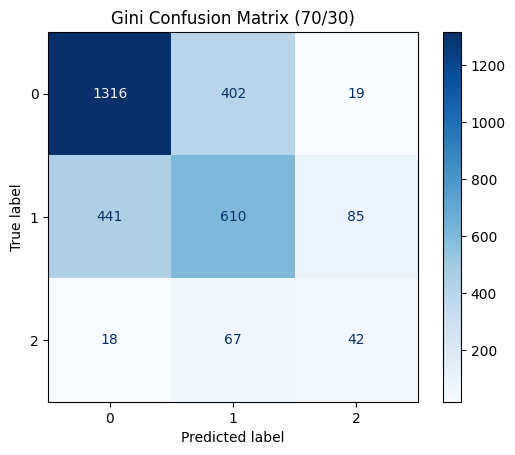

In [6]:
# Gini Decision Tree - 70/30 Split

X_train_70, X_test_70, y_train_70, y_test_70 = train_test_split(
    X, y,
    test_size=0.3,
    random_state=1,
    stratify=y
)

gini_model_70 = DecisionTreeClassifier(
    criterion='gini',
    random_state=1
)

gini_model_70.fit(X_train_70, y_train_70)

y_pred_70 = gini_model_70.predict(X_test_70)

accuracy_70 = accuracy_score(y_test_70, y_pred_70)

print("Gini Accuracy (70/30):", accuracy_70)

cm_70 = confusion_matrix(y_test_70, y_pred_70)

ConfusionMatrixDisplay(
    confusion_matrix=cm_70,
    display_labels=[0, 1, 2]
).plot(cmap='Blues')

plt.title("Gini Confusion Matrix (70/30)")
plt.show()

### Gini Decision Tree – 70/30 Split
Using the Gini criterion with a 70/30 split, the model achieved **65.6% accuracy**. It correctly classified 1,316 Low, 610 Medium, and 42 High stress cases. However, only 42 out of 127 High stress cases were correctly identified (33.1%), showing that the model still struggles with this class.

### Gini Decision Tree – Results

The Gini Decision Tree was tested using three train-test splits to compare its performance.

| Train/Test Split | Accuracy | High Stress Recall |
|---|---|---|
| 90/10 | 66.40% | 33.3% |
| 80/20 | 65.2% | 29.4% |
| 70/30 | 65.60% | 33.1% |

The 90/10 split achieved the highest accuracy (66.4%), while the 70/30 split had a slightly lower accuracy (65.6%). All three splits showed difficulty identifying High stress cases, which may be related to the small number of samples in this class.

## **Decision Tree Classification Using Entropy**

The Decision Tree classifier was applied to the dataset using the Entropy criterion (Information Gain) with three different train-test partitions:

90% Training  10% Testing

80% Training  20% Testing

70% Training  30% Testing


Entropy Accuracy(90/10): 0.662
Entropy Recall(90/10): [0.7417103  0.58701299 0.26190476]


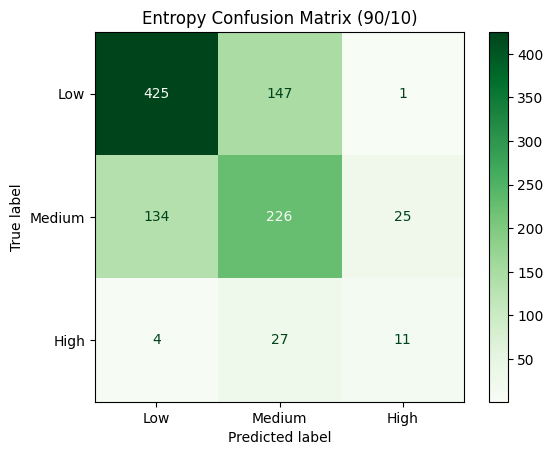

In [7]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.1,random_state=1)

clf=DecisionTreeClassifier(criterion="entropy", random_state=1)
clf=clf.fit(X_train,y_train)
y_pred=clf.predict(X_test)

print("Entropy Accuracy(90/10):", accuracy_score(y_test, y_pred))
print("Entropy Recall(90/10):", recall_score(y_test, y_pred, average= None))

labels = ["Low", "Medium","High"]
cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=labels
)

disp.plot(cmap="Greens")


plt.title("Entropy Confusion Matrix (90/10)")
plt.show()

###Entropy Decision Tree – 90/10 Split

Using the Entropy criterion with a 90/10 split, the model achieved 66.2% accuracy. It performed best in identifying Class 0, while Class 2 had the lowest recall.

Entropy Accuracy(80/20): 0.669
Entropy Recall(80/20): [0.75765306 0.58038147 0.23333333]


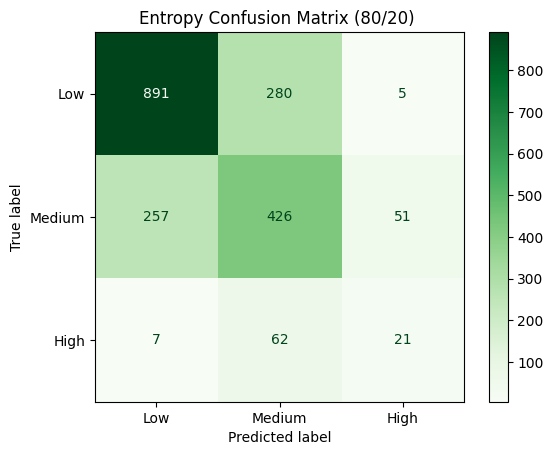

In [8]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=1)

clf=DecisionTreeClassifier(criterion="entropy", random_state=1)
clf=clf.fit(X_train,y_train)
y_pred=clf.predict(X_test)

print("Entropy Accuracy(80/20):", accuracy_score(y_test, y_pred))
print("Entropy Recall(80/20):", recall_score(y_test, y_pred, average= None))

labels = ["Low", "Medium","High"]
cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=labels
)

disp.plot(cmap="Greens")

plt.title("Entropy Confusion Matrix (80/20) ")
plt.show()

###Entropy Decision Tree – 80/20 Split

Using the Entropy criterion with a 80/20 split, the model achieved 66.9% accuracy. although Class 2 remained the most difficult class to identify correctly.

Entropy Accuracy(70/30): 0.6753333333333333
Entropy Recall(70/30): [0.76201373 0.59070599 0.2481203 ]


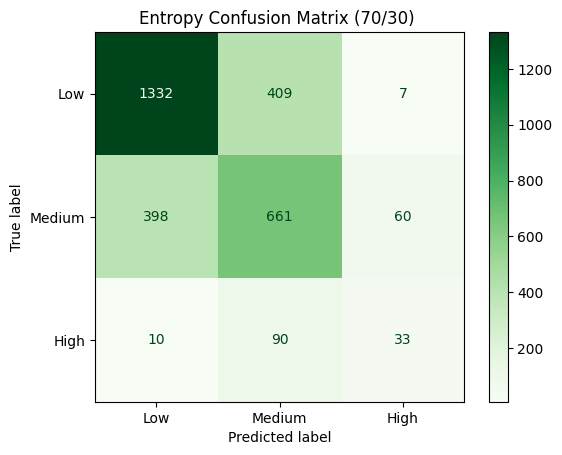

In [9]:

X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.3,random_state=1)

clf=DecisionTreeClassifier(criterion="entropy", random_state=1)
clf=clf.fit(X_train,y_train)
y_pred=clf.predict(X_test)

print("Entropy Accuracy(70/30):", accuracy_score(y_test, y_pred))
print("Entropy Recall(70/30):", recall_score(y_test, y_pred, average= None))

cn=df['Daily_Stress_Level'].unique()

labels = ["Low", "Medium","High"]
cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=labels
)

disp.plot(cmap="Greens")

plt.title("Entropy Confusion Matrix (70/30) ")
plt.show()

###Entropy Decision Tree – 70/30 Split

Using the Entropy criterion with a 70/30 split, the model achieved 67.53% accuracy. This partition provided the best overall performance,The model maintained good recall for Class 0 but struggled with Class 2.

### Enropy Decision Tree – Results

The Enropy Decision Tree was tested using three train-test splits to compare its performance.


| Train/Test Split | Accuracy | High Stress Recall |
|---|---|---|
| 90/10 | 66.2% | 26.19% |
| 80/20 | 66.9% | 23.33% |
| 70/30 | 67.5% | 24.8% |


**Results Discussion :**

The Decision Tree classifier using the Entropy criterion was evaluated with three partition sizes: 90/10, 80/20, and 70/30. The accuracy increased slightly from 66.2% to 66.9% and 67.5% as the partition size changed. Recall was consistently highest for Class 0 (74.2%-76.2%), moderate for Class 1 (58.0%-59.1%), and lowest for Class 2 (23.3%-26.2%), indicating that the model had difficulty identifying Class 2. Overall, the 70/30 partition achieved the best performance.

### **Class Merging**

Since Class 2 achieved the lowest recall across all train-test splits, the model had difficulty correctly identifying samples belonging to this class. Therefore, Class 2 was merged with Class 1 to reduce class imbalance and simplify the classification task.

In [10]:
df['Daily_Stress_Level'] = df['Daily_Stress_Level'].replace({2:1})
df['Daily_Stress_Level'].value_counts()

,count
Daily_Stress_Level,
0,5789
1,4211


In [11]:
fn = df.keys().tolist()[:-1]
X=df[fn]
y=df['Daily_Stress_Level']

#Gini Decision Tree – After Merging High and Medium

In [12]:
# Merge Medium and High stress into one class
df_binary = df.copy()

df_binary['Daily_Stress_Level'] = df_binary['Daily_Stress_Level'].replace({
    2: 1
})

print(df_binary['Daily_Stress_Level'].value_counts())

Daily_Stress_Level
0    5789
1    4211
Name: count, dtype: int64


Gini Accuracy (90/10) - After Merging: 0.719


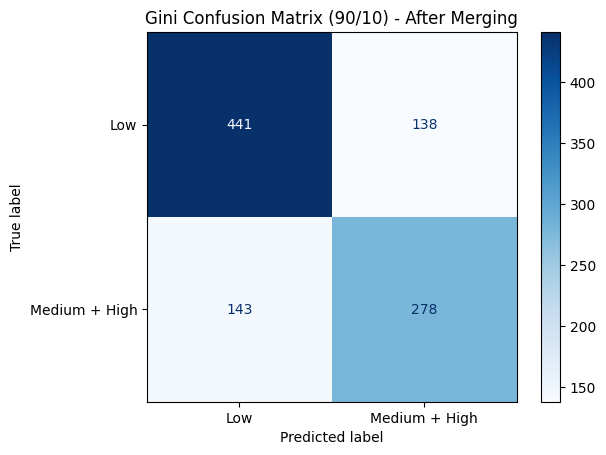

In [13]:
# Gini Decision Tree - 90/10 Split (After Merging)

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

X_binary = df_binary.drop('Daily_Stress_Level', axis=1)
y_binary = df_binary['Daily_Stress_Level']

X_train_b90, X_test_b90, y_train_b90, y_test_b90 = train_test_split(
    X_binary, y_binary,
    test_size=0.1,
    random_state=1,
    stratify=y_binary
)

gini_b90 = DecisionTreeClassifier(
    criterion='gini',
    random_state=1
)

gini_b90.fit(X_train_b90, y_train_b90)

y_pred_b90 = gini_b90.predict(X_test_b90)

accuracy_b90 = accuracy_score(y_test_b90, y_pred_b90)
print("Gini Accuracy (90/10) - After Merging:", accuracy_b90)

cm_b90 = confusion_matrix(y_test_b90, y_pred_b90, labels=[0, 1])

ConfusionMatrixDisplay(
    confusion_matrix=cm_b90,
    display_labels=['Low', 'Medium + High']
).plot(cmap='Blues')

plt.title("Gini Confusion Matrix (90/10) - After Merging")
plt.show()

The Gini Decision Tree achieved 71.9% accuracy using the 90/10 split after merging Medium and High stress levels. The model correctly classified 441 Low and 278 Medium + High cases, but some predictions were still incorrect.

Gini Accuracy (80/20) - After Merging: 0.697


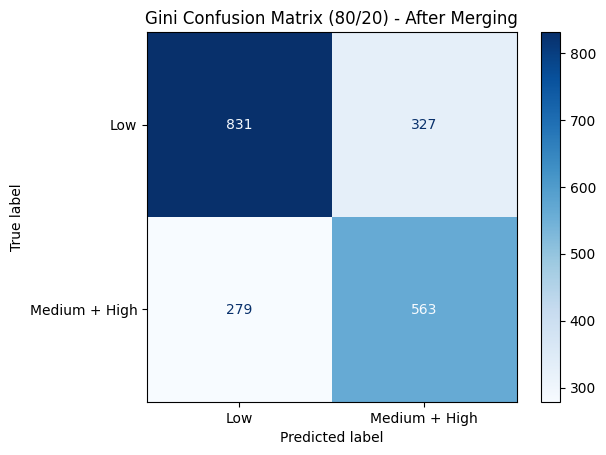

In [14]:
# Gini Decision Tree - 80/20 Split (After Merging)

X_train_b80, X_test_b80, y_train_b80, y_test_b80 = train_test_split(
    X_binary, y_binary,
    test_size=0.2,
    random_state=1,
    stratify=y_binary
)

gini_b80 = DecisionTreeClassifier(
    criterion='gini',
    random_state=1
)

gini_b80.fit(X_train_b80, y_train_b80)

y_pred_b80 = gini_b80.predict(X_test_b80)

accuracy_b80 = accuracy_score(y_test_b80, y_pred_b80)
print("Gini Accuracy (80/20) - After Merging:", accuracy_b80)

cm_b80 = confusion_matrix(y_test_b80, y_pred_b80, labels=[0, 1])

ConfusionMatrixDisplay(
    confusion_matrix=cm_b80,
    display_labels=['Low', 'Medium + High']
).plot(cmap='Blues')

plt.title("Gini Confusion Matrix (80/20) - After Merging")
plt.show()

The Gini Decision Tree achieved **69.7% accuracy** using the 80/20 split after merging Medium and High stress levels. The model correctly classified 831 Low and 563 Medium + High cases, but some cases were still misclassified. The accuracy was slightly lower than the 90/10 split.

Gini Accuracy (70/30) - After Merging: 0.7006666666666667


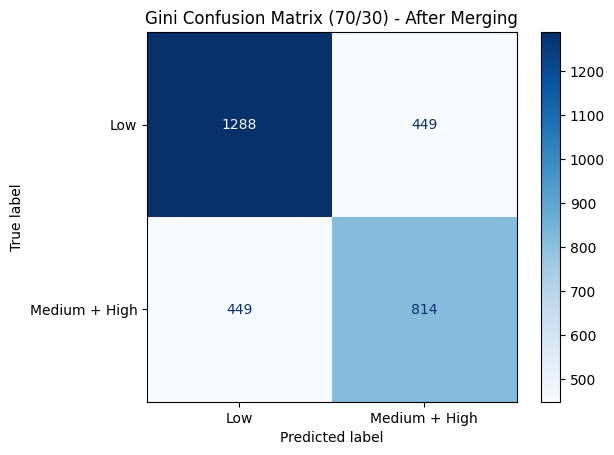

In [15]:
# Gini Decision Tree - 70/30 Split (After Merging)

X_train_b70, X_test_b70, y_train_b70, y_test_b70 = train_test_split(
    X_binary, y_binary,
    test_size=0.3,
    random_state=1,
    stratify=y_binary
)

gini_b70 = DecisionTreeClassifier(
    criterion='gini',
    random_state=1
)

gini_b70.fit(X_train_b70, y_train_b70)

y_pred_b70 = gini_b70.predict(X_test_b70)

accuracy_b70 = accuracy_score(y_test_b70, y_pred_b70)
print("Gini Accuracy (70/30) - After Merging:", accuracy_b70)

cm_b70 = confusion_matrix(y_test_b70, y_pred_b70, labels=[0, 1])

ConfusionMatrixDisplay(
    confusion_matrix=cm_b70,
    display_labels=['Low', 'Medium + High']
).plot(cmap='Blues')

plt.title("Gini Confusion Matrix (70/30) - After Merging")
plt.show()

The Gini Decision Tree achieved **70.07% accuracy** using the 70/30 train-test split after merging Medium and High stress levels. The model correctly classified 1,288 Low and 814 Medium + High cases. However, 449 Medium + High cases were incorrectly predicted as Low. The accuracy was higher than the 80/20 split (69.7%) but lower than the 90/10 split (71.9%).

### Gini Decision Tree – Comparison Before and After Merging

| Train/Test Split | Before Merging | After Merging |
|---|---|---|
| 90/10 | 66.40% | 71.90% |
| 80/20 | 65.20% | 69.70% |
| 70/30 | 65.60% | 70.07% |

**Average Accuracy Before Merging:** 65.73%

**Average Accuracy After Merging:** 70.56%

**Improvement:** Approximately 4.82 percentage points.

### Analysis and Interpretation

The results show an improvement in overall accuracy after merging Medium and High stress levels into one class.

The average accuracy increased from 65.73% to 70.56%, representing an improvement of approximately 4.82 percentage points.

The 90/10 split achieved the highest accuracy (71.90%) after merging, followed by the 70/30 split (70.07%) and the 80/20 split (69.70%).

This improvement suggests that reducing the number of classes made the classification task easier. However, some Medium + High stress cases were still incorrectly classified as Low, indicating that the model continues to have classification limitations.

## **Decision Tree Classification Using Entropy**

The same Decision Tree classifier using the Entropy criterion was applied after merging Class 2 with Class 1 using the same train-test partitions.


Entropy Accuracy(90/10) After Merging: 0.728
Entropy Recall(90/10) After Merging: [0.7434555  0.70725995]


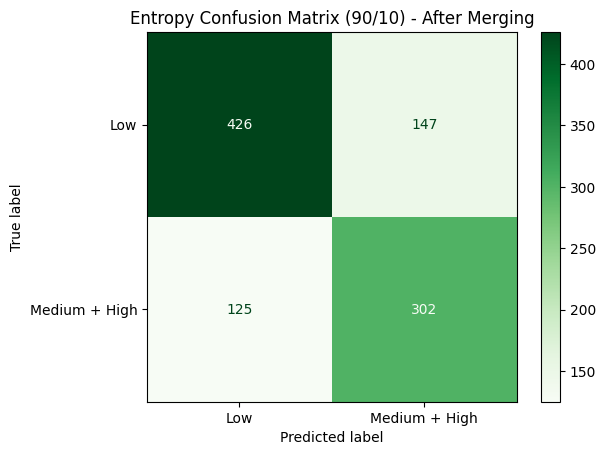

In [16]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.1,random_state=1)

clf=DecisionTreeClassifier(criterion="entropy", random_state=1)
clf=clf.fit(X_train,y_train)
y_pred=clf.predict(X_test)

print("Entropy Accuracy(90/10) After Merging:", accuracy_score(y_test, y_pred))
print("Entropy Recall(90/10) After Merging:", recall_score(y_test, y_pred, average= None))

labels = ["Low", "Medium + High"]
cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=labels
)

disp.plot(cmap="Greens")


plt.title("Entropy Confusion Matrix (90/10) - After Merging")
plt.show()

###Entropy Decision Tree – 90/10 Split **After Merging**

Using the Entropy criterion with a 90/10 split after class merging, the model achieved 72.8% accuracy. It correctly identified 74.3% of Class 0 cases and 70.7% of Class 1 cases, showing balanced performance across both classes.

Entropy Accuracy(80/20) After Merging: 0.7185
Entropy Recall(80/20) After Merging: [0.74659864 0.67839806]


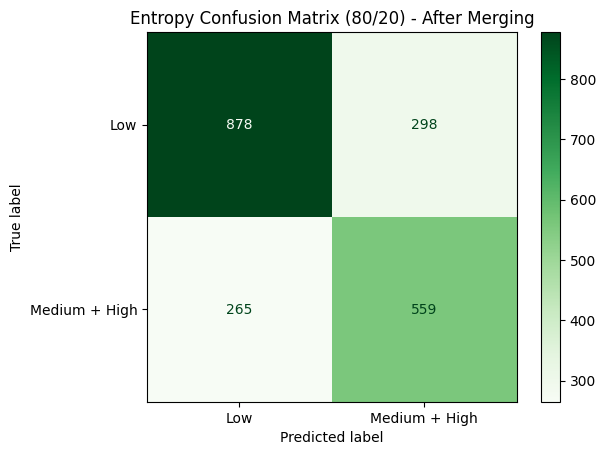

In [17]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=1)

clf=DecisionTreeClassifier(criterion="entropy", random_state=1)
clf=clf.fit(X_train,y_train)
y_pred=clf.predict(X_test)

print("Entropy Accuracy(80/20) After Merging:", accuracy_score(y_test, y_pred))
print("Entropy Recall(80/20) After Merging:", recall_score(y_test, y_pred, average= None))

labels = ["Low", "Medium + High"]
cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=labels
)

disp.plot(cmap="Greens")

plt.title("Entropy Confusion Matrix (80/20) - After Merging")
plt.show()

###Entropy Decision Tree – 80/20 Split **After Merging**

Using the Entropy criterion with an 80/20 split after class merging, the model achieved 71.9% accuracy. The recall values were 74.7% for Class 0 and 67.8% for Class 1, indicating good classification performance.

Entropy Accuracy(70/30) After Merging: 0.721
Entropy Recall(70/30) After Merging: [0.74828375 0.68290735]


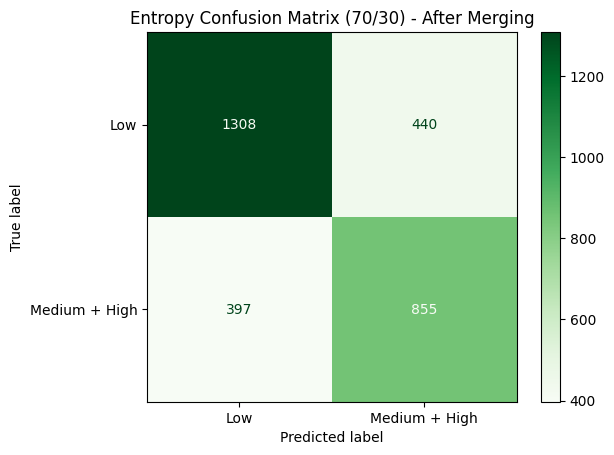

In [18]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.3,random_state=1)

clf=DecisionTreeClassifier(criterion="entropy", random_state=1)
clf=clf.fit(X_train,y_train)

y_pred=clf.predict(X_test)


print("Entropy Accuracy(70/30) After Merging:", accuracy_score(y_test, y_pred))
print("Entropy Recall(70/30) After Merging:", recall_score(y_test, y_pred, average= None))


labels = ["Low", "Medium + High"]
cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=labels
)

disp.plot(cmap="Greens")


plt.title("Entropy Confusion Matrix (70/30) - After Merging")
plt.show()

###Entropy Decision Tree – 70/30 Split **After Merging**

Using the Entropy criterion with a 70/30 split after class merging, the model achieved 72.1% accuracy. It correctly identified 74.8% of Class 0 cases and 68.3% of Class 1 cases, maintaining strong performance for both classes.

### **Entropy Results After Merging Classes**


The Enropy Decision Tree was tested using three train-test splits to compare its performance.


| Train/Test Split | Accuracy | Medium + High Stress Recall |
|---|---|---|
| 90/10 | 72.8% | 70.7% |
| 80/20 | 71.9% | 67.8% |
| 70/30 | 72.1% | 68.3% |


Results Discussion :

After merging Class 2 with Class 1, the model achieved its best performance using the 90/10 partition, with an accuracy of 72.8%. Therefore, this partition was selected for further analysis.

##**Performance After Class Merging**

Compared with the original three-class dataset, class merging improved the model's performance. The accuracy increased from 67.5% (best result before merging) to 72.8% after merging, suggesting that reducing class imbalance helped the Decision Tree classifier make more accurate predictions.